In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

In [3]:
DATA_DIR = Path("datasets/cicids2017/versions/1/MachineLearningCVE")

print("Czy katalog istnieje:", DATA_DIR.exists())

csv_files = list(DATA_DIR.glob("*.csv"))

print("Liczba znalezionych plików CSV:", len(csv_files))

for file in csv_files:
    print(file.name)

Czy katalog istnieje: True
Liczba znalezionych plików CSV: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Friday-WorkingHours-Morning.pcap_ISCX.csv
Monday-WorkingHours.pcap_ISCX.csv
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Tuesday-WorkingHours.pcap_ISCX.csv
Wednesday-workingHours.pcap_ISCX.csv


In [4]:
#Wczytanie plików do df
dataframes = []

for file in csv_files:
    print("Wczytywanie:", file.name)

    df = pd.read_csv(file, low_memory=False)

    dataframes.append(df)

# Połączenie wszystkich plików
data = pd.concat(dataframes, ignore_index=True)

print("Dane zostały załadowane!")
print("Liczba wierszy i kolumn:", data.shape)

display(data.head())

Wczytywanie: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Wczytywanie: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Wczytywanie: Friday-WorkingHours-Morning.pcap_ISCX.csv
Wczytywanie: Monday-WorkingHours.pcap_ISCX.csv
Wczytywanie: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Wczytywanie: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Wczytywanie: Tuesday-WorkingHours.pcap_ISCX.csv
Wczytywanie: Wednesday-workingHours.pcap_ISCX.csv
Dane zostały załadowane!
Liczba wierszy i kolumn: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [5]:
data.info()
display(data.isnull().sum().sort_values(ascending=False))

<class 'pandas.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0    Destination Port             int64  
 1    Flow Duration                int64  
 2    Total Fwd Packets            int64  
 3    Total Backward Packets       int64  
 4   Total Length of Fwd Packets   int64  
 5    Total Length of Bwd Packets  int64  
 6    Fwd Packet Length Max        int64  
 7    Fwd Packet Length Min        int64  
 8    Fwd Packet Length Mean       float64
 9    Fwd Packet Length Std        float64
 10  Bwd Packet Length Max         int64  
 11   Bwd Packet Length Min        int64  
 12   Bwd Packet Length Mean       float64
 13   Bwd Packet Length Std        float64
 14  Flow Bytes/s                  float64
 15   Flow Packets/s               float64
 16   Flow IAT Mean                float64
 17   Flow IAT Std                 float64
 18   Flow IAT Max                 int

Flow Bytes/s                   1358
 Flow Duration                    0
 Destination Port                 0
 Total Backward Packets           0
Total Length of Fwd Packets       0
                               ... 
Idle Mean                         0
 Idle Std                         0
 Idle Max                         0
 Idle Min                         0
 Label                            0
Length: 79, dtype: int64

In [6]:
# Czyszczenie danych
data.columns = data.columns.str.strip()

data.dropna(how="all", inplace=True)

data.replace([np.inf, -np.inf], np.nan, inplace=True)

duplicates = data.duplicated().sum()

print("Liczba duplikatów:", duplicates)

data.drop_duplicates(inplace=True)

data["Label"] = data["Label"].astype("string").str.strip()

data.dropna(inplace=True)

data.reset_index(drop=True, inplace=True)

C:\Users\Milana\AppData\Local\Temp\ipykernel_26192\2958601381.py:4: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.dropna(how="all", inplace=True)


Liczba duplikatów: 308381


C:\Users\Milana\AppData\Local\Temp\ipykernel_26192\2958601381.py:12: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop_duplicates(inplace=True)
C:\Users\Milana\AppData\Local\Temp\ipykernel_26192\2958601381.py:16: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.dropna(inplace=True)
C:\Users\Milana\AppData\Local\Temp\ipykernel_26192\2958601381.py:18: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.reset_index(drop=True, inplace=True)


In [7]:
class_counts = data["Label"].value_counts()

display(class_counts)

Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64

In [8]:
class_percentages = data["Label"].value_counts(normalize=True) * 100

display(class_percentages.round(2))

Label
BENIGN                        83.11
DoS Hulk                       6.86
DDoS                           5.08
PortScan                        3.6
DoS GoldenEye                  0.41
FTP-Patator                    0.24
DoS slowloris                  0.21
DoS Slowhttptest               0.21
SSH-Patator                    0.13
Bot                            0.08
Web Attack � Brute Force       0.06
Web Attack � XSS               0.03
Infiltration                    0.0
Web Attack � Sql Injection      0.0
Heartbleed                      0.0
Name: proportion, dtype: Float64

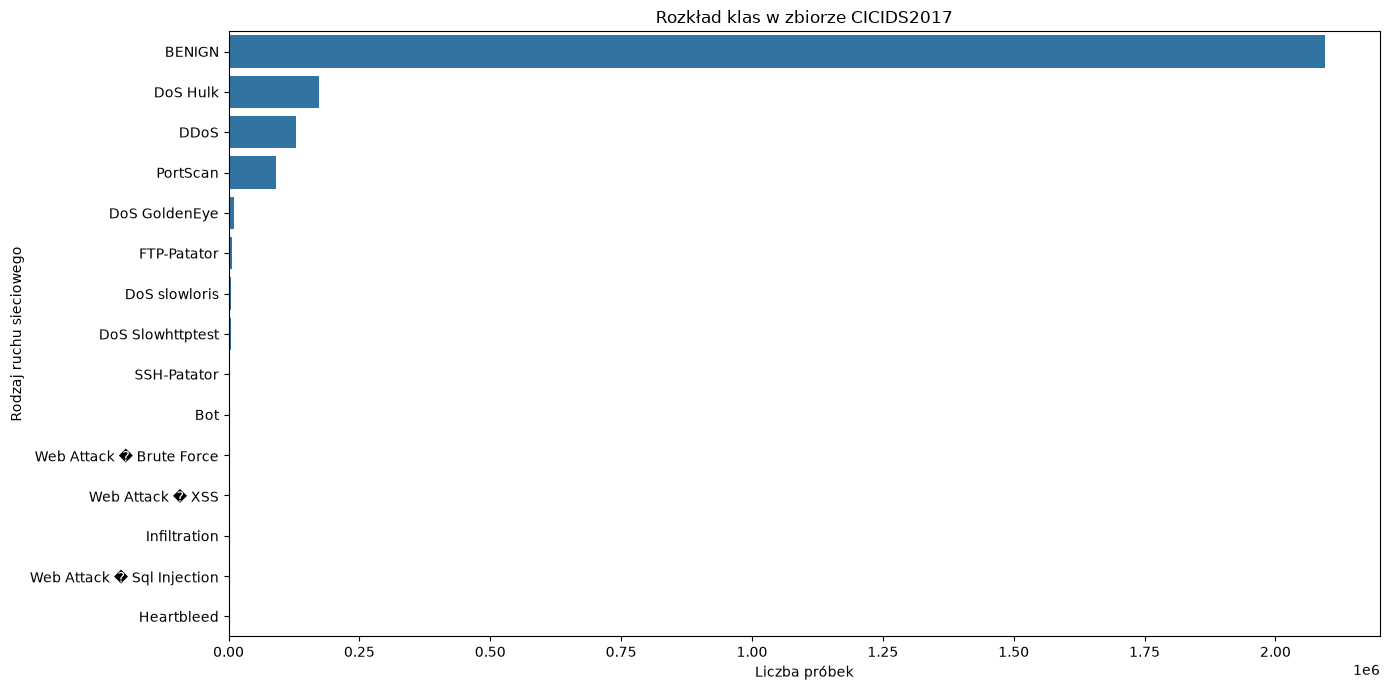

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))

sns.countplot(
    data=data,
    y="Label",
    order=data["Label"].value_counts().index
)

plt.title("Rozkład klas w zbiorze CICIDS2017")
plt.xlabel("Liczba próbek")
plt.ylabel("Rodzaj ruchu sieciowego")

plt.tight_layout()
plt.show()

In [12]:
OUTPUT_FILE = "datasets/processed/CICIDS2017_cleaned.csv"

data.to_csv(OUTPUT_FILE, index=False)

print("Rozmiar datasetu:", data.shape)

Rozmiar datasetu: (2520798, 79)


In [ ]:
#Dodanie etykiet binarnych
data["Label_Binary"] = (
    data["Label"]
    .apply(lambda x: 0 if x == "BENIGN" else 1)
)

#Dodanie etykiet wieloklasowych
data["Label_Multiclass"] = data["Label"]

print("Binary labels:")
display(data["Label_Binary"].value_counts())

print("Multiclass labels:")
display(data["Label_Multiclass"].value_counts())

Binary labels:


Label_Binary
0    2095057
1     425741
Name: count, dtype: int64

Multiclass labels:


Label_Multiclass
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: Int64

In [15]:
#Przygotowanie cech i etykiet
X = data.drop(
    columns=["Label", "Label_Binary", "Label_Multiclass"]
)

y_binary = data["Label_Binary"]
y_multiclass = data["Label_Multiclass"]

print("Features shape:", X.shape)
print("Binary target shape:", y_binary.shape)
print("Multiclass target shape:", y_multiclass.shape)

Features shape: (2520798, 78)
Binary target shape: (2520798,)
Multiclass target shape: (2520798,)


In [18]:
#Przyekonwertowanie cech na dane numeryczne
X = X.apply(pd.to_numeric, errors="coerce")

X = X.fillna(X.median())

In [ ]:
#Podział na train i test dla klasyfikacji binarnej
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X,
    y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

print("Binary")
print("X_train:", X_train_bin.shape)
print("X_test:", X_test_bin.shape)

X_train: (2016638, 78)
X_test: (504160, 78)


In [ ]:
#Skalowanie danych 
scaler_binary = StandardScaler()

X_train_bin_scaled = scaler_binary.fit_transform(X_train_bin)
X_test_bin_scaled = scaler_binary.transform(X_test_bin)

In [24]:
#Podział na train i test dla klasyfikacji wieloklasowej
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X,
    y_multiclass,
    test_size=0.2,
    random_state=42,
    stratify=y_multiclass
)

print("Multiclass:")
print("X_train:", X_train_multi.shape)
print("X_test:", X_test_multi.shape)

Multiclass:
X_train: (2016638, 78)
X_test: (504160, 78)


In [25]:
#Skalowanie danych
scaler_multi = StandardScaler()

X_train_multi_scaled = scaler_multi.fit_transform(X_train_multi)
X_test_multi_scaled = scaler_multi.transform(X_test_multi)

In [28]:
#Zbalansowanie klas (binarna)
binary_classes = np.unique(y_train_bin)

binary_weights = compute_class_weight(
    class_weight="balanced",
    classes=binary_classes,
    y=y_train_bin
)

binary_class_weights = dict(zip(binary_classes, binary_weights))

print("Binary class weights:")
print(binary_class_weights)

Binary class weights:
{np.int64(0): np.float64(0.6016061621257186), np.int64(1): np.float64(2.9604806910300563)}


In [29]:
#Zbalansowanie klas (wieloklasowa)
multi_classes = np.unique(y_train_multi)

multi_weights = compute_class_weight(
    class_weight="balanced",
    classes=multi_classes,
    y=y_train_multi
)

multi_class_weights = dict(zip(multi_classes, multi_weights))

print("Multiclass class weights:")
print(multi_class_weights)

Multiclass class weights:
{'BENIGN': np.float64(0.08021415495009582), 'Bot': np.float64(86.29174154899444), 'DDoS': np.float64(1.3127743439018595), 'DoS GoldenEye': np.float64(16.3376513954713), 'DoS Hulk': np.float64(0.9722696712637194), 'DoS Slowhttptest': np.float64(32.147903714331264), 'DoS slowloris': np.float64(31.207644692045807), 'FTP-Patator': np.float64(28.33351598173516), 'Heartbleed': np.float64(14938.059259259258), 'Infiltration': np.float64(4635.9494252873565), 'PortScan': np.float64(1.852974065651345), 'SSH-Patator': np.float64(52.21069255663431), 'Web Attack � Brute Force': np.float64(114.3218820861678), 'Web Attack � Sql Injection': np.float64(7908.38431372549), 'Web Attack � XSS': np.float64(257.5527458492976)}


In [30]:
#Zapisanie
OUTPUT_DIR = Path("datasets/cicids2017/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

pd.DataFrame(X_train_bin_scaled, columns=X.columns).to_csv(
    OUTPUT_DIR / "X_train_binary.csv", index=False
)

pd.DataFrame(X_test_bin_scaled, columns=X.columns).to_csv(
    OUTPUT_DIR / "X_test_binary.csv", index=False
)

y_train_bin.to_csv(OUTPUT_DIR / "y_train_binary.csv", index=False)
y_test_bin.to_csv(OUTPUT_DIR / "y_test_binary.csv", index=False)

pd.DataFrame(X_train_multi_scaled, columns=X.columns).to_csv(
    OUTPUT_DIR / "X_train_multiclass.csv", index=False
)

pd.DataFrame(X_test_multi_scaled, columns=X.columns).to_csv(
    OUTPUT_DIR / "X_test_multiclass.csv", index=False
)

y_train_multi.to_csv(OUTPUT_DIR / "y_train_multiclass.csv", index=False)
y_test_multi.to_csv(OUTPUT_DIR / "y_test_multiclass.csv", index=False)